TRAVEL INSURANCE PURCHASE PREDICTION:

Dataset loaded successfully!
Dataset Shape: (1987, 10)
INITIAL DATA INSPECTION:

First 5 rows:
   Unnamed: 0  Age               Employment Type GraduateOrNot  AnnualIncome  \
0           0   31             Government Sector           Yes        400000   
1           1   31  Private Sector/Self Employed           Yes       1250000   
2           2   34  Private Sector/Self Employed           Yes        500000   
3           3   28  Private Sector/Self Employed           Yes        700000   
4           4   28  Private Sector/Self Employed           Yes        700000   

   FamilyMembers  ChronicDiseases FrequentFlyer EverTravelledAbroad  \
0              6                1            No                  No   
1              7                0            No                  No   
2              4                1            No                  No   
3              3                1            No                  No   
4              8              

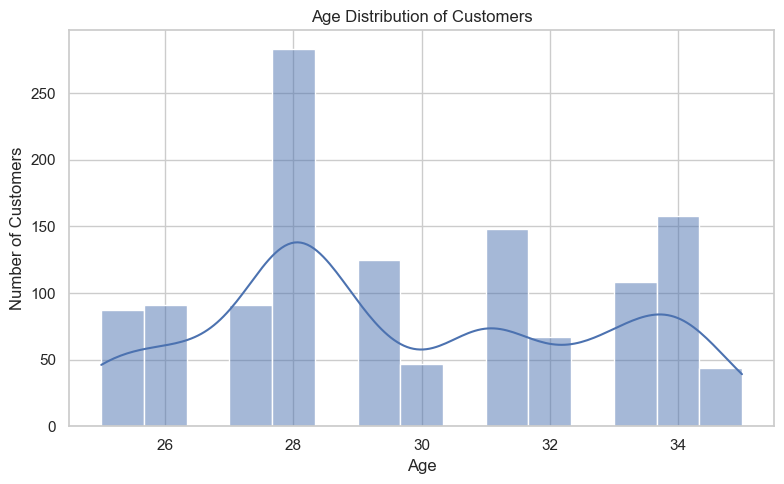

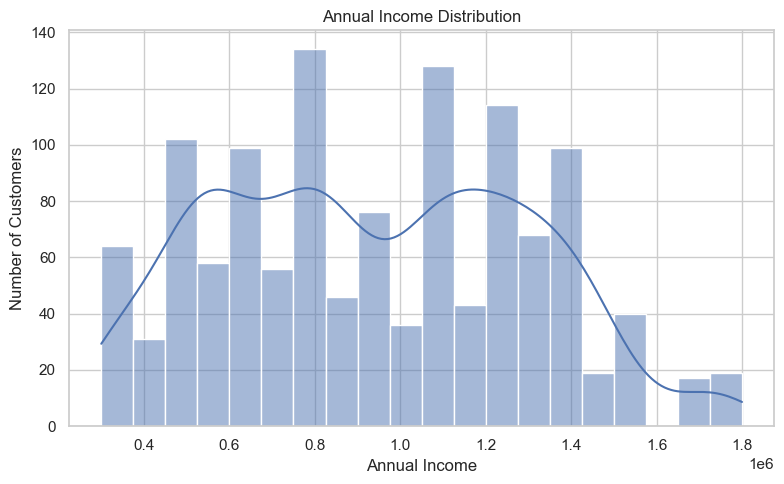

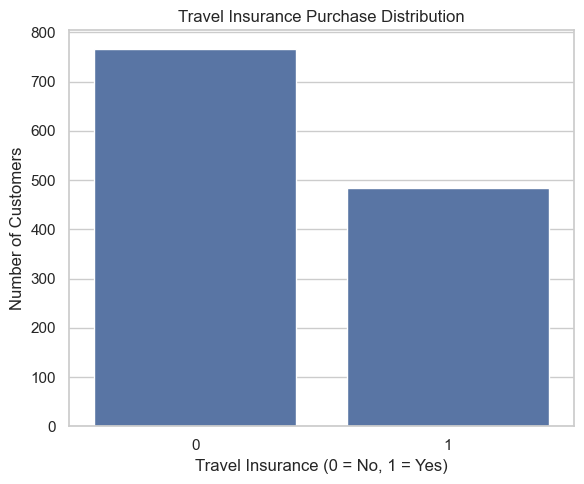

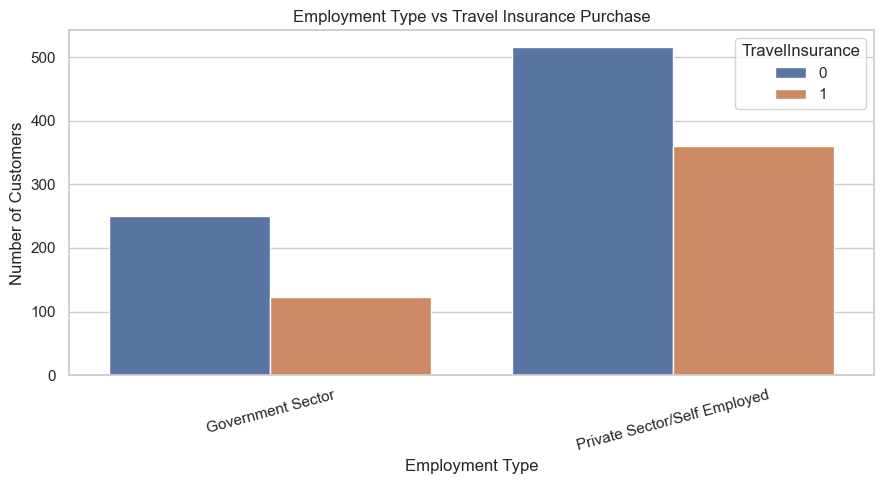

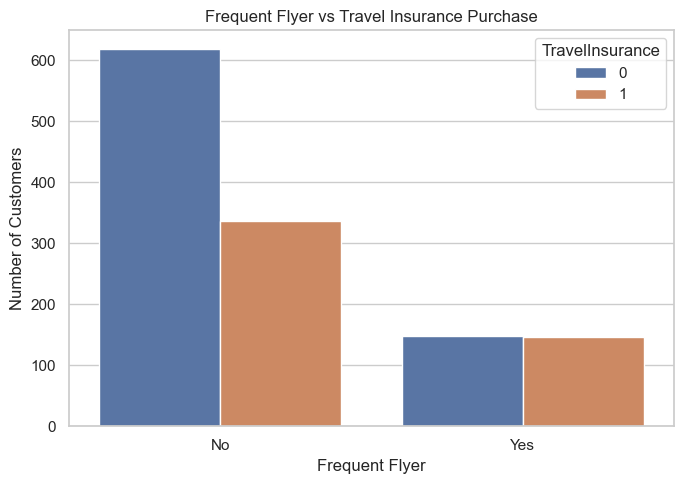

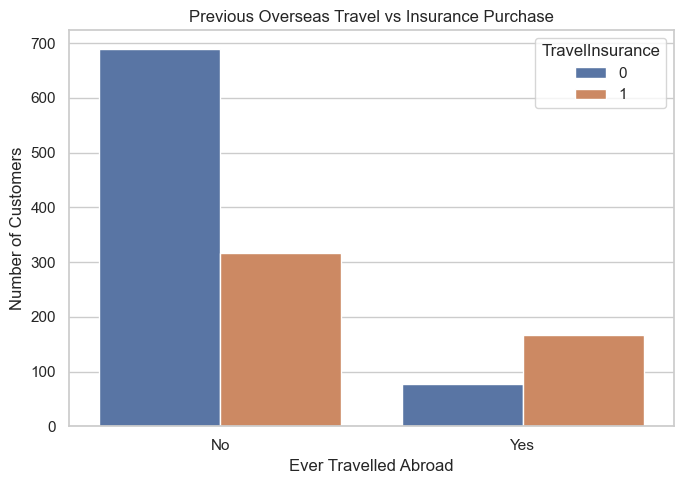

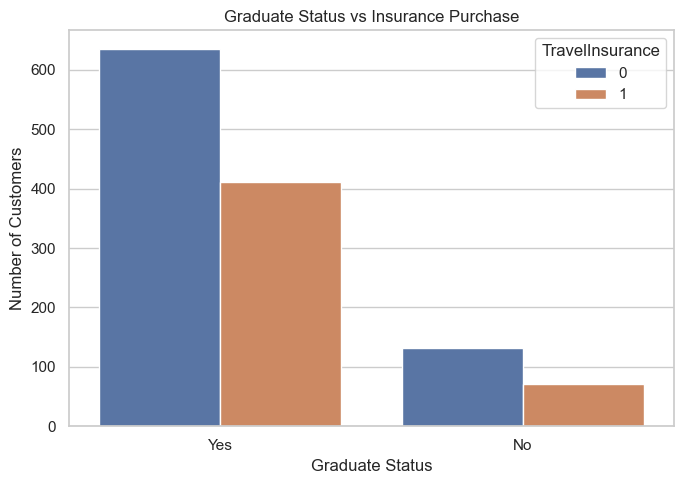

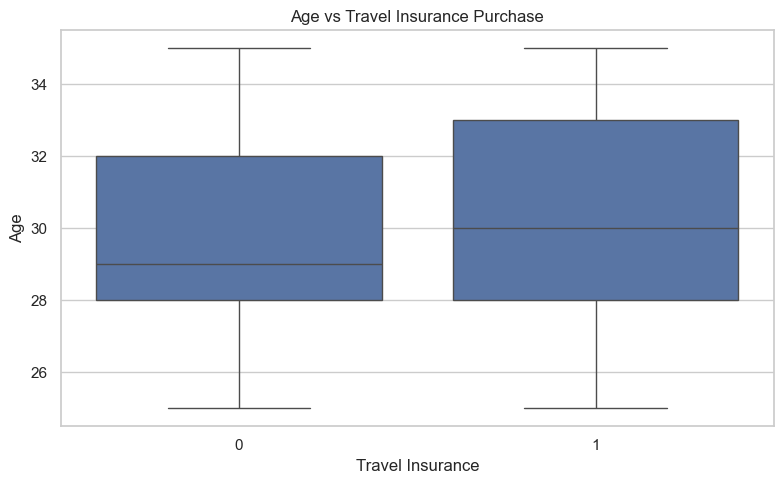

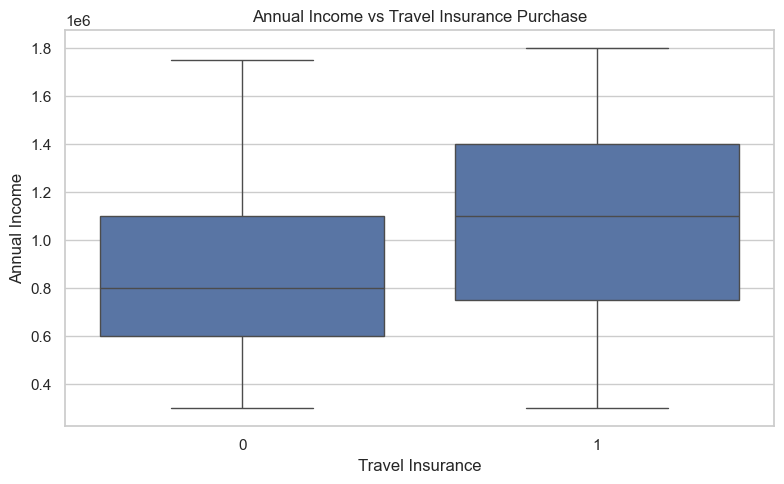

OUTLIER CHECK:
Age: 0 potential outliers
AnnualIncome: 0 potential outliers
FamilyMembers: 0 potential outliers
CORRELATION ANALYSIS:


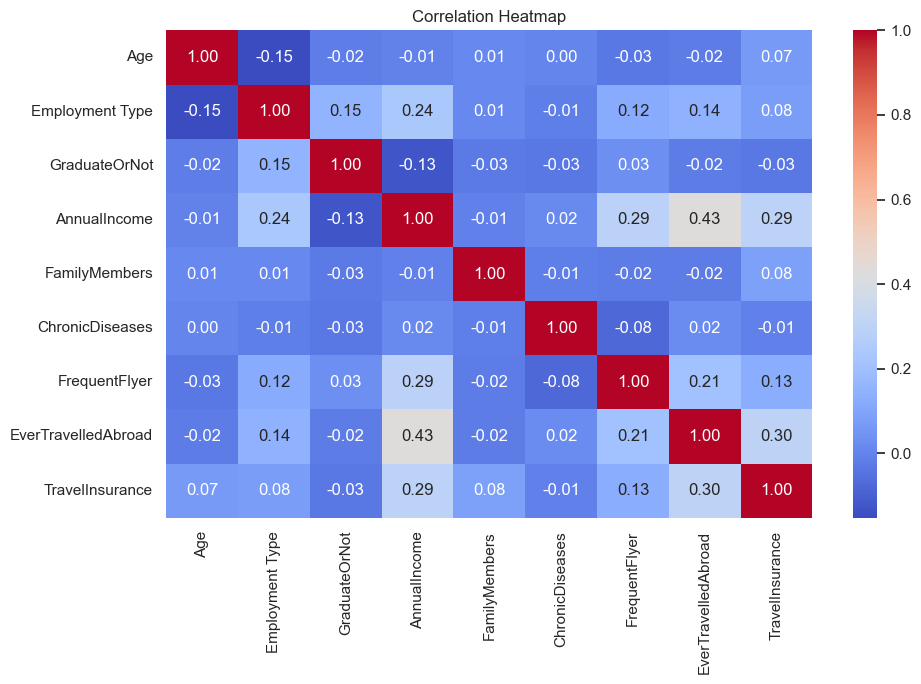

FEATURE ENGINEERING:
Created feature: IncomePerFamilyMember

Updated columns:
['Age', 'Employment Type', 'GraduateOrNot', 'AnnualIncome', 'FamilyMembers', 'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad', 'TravelInsurance', 'IncomePerFamilyMember']

Features:
['Age', 'Employment Type', 'GraduateOrNot', 'AnnualIncome', 'FamilyMembers', 'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad', 'IncomePerFamilyMember']

Target:
TravelInsurance
TRAIN TEST SPLIT:
Training samples: 999
Testing samples: 250
MODEL TRAINING AND EVALUATION:

------------------------------------------------------------
Logistic Regression
------------------------------------------------------------
Accuracy : 0.6520
Precision: 0.5833
Recall   : 0.3608
F1 Score : 0.4459
ROC-AUC  : 0.6459

------------------------------------------------------------
Decision Tree
------------------------------------------------------------
Accuracy : 0.7440
Precision: 0.8667
Recall   : 0.4021
F1 Score : 0.5493
ROC-AUC  : 

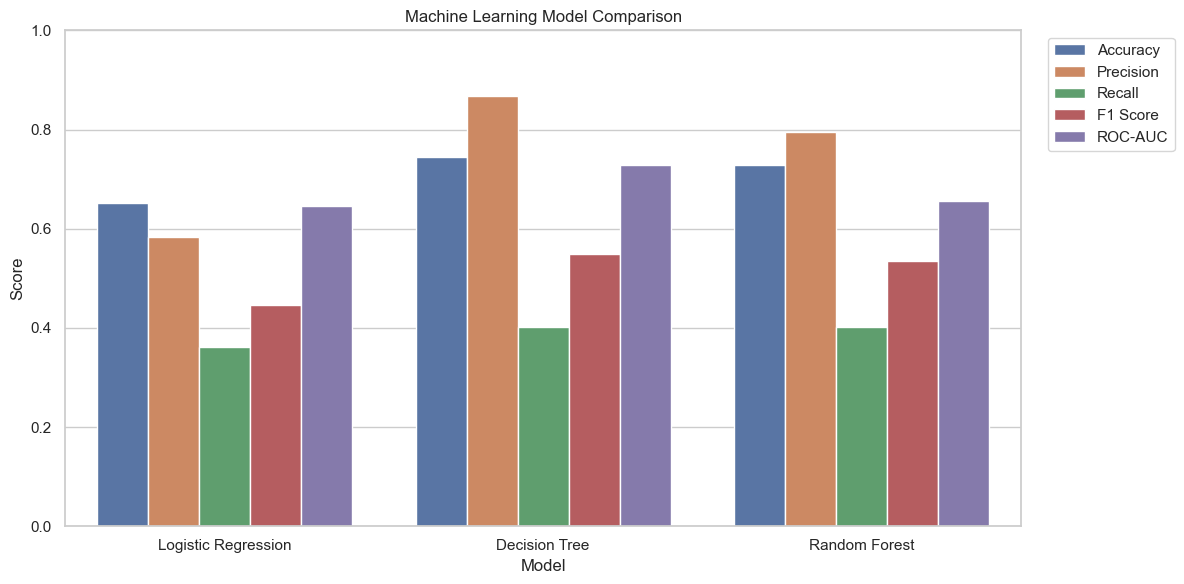

SELECTED MODEL:
Selected model: Decision Tree
Selection basis: Highest F1 Score


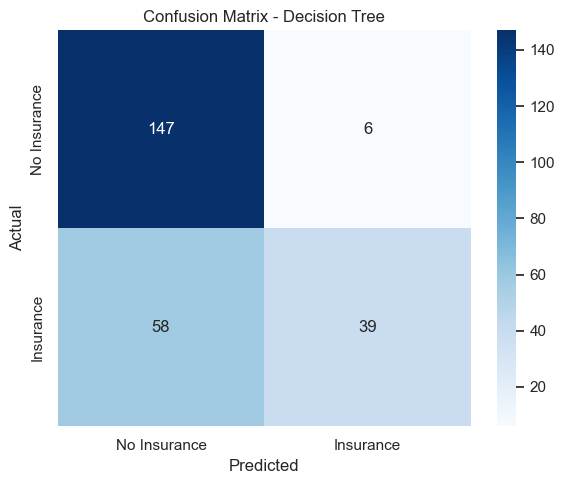

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.72      0.96      0.82       153
           1       0.87      0.40      0.55        97

    accuracy                           0.74       250
   macro avg       0.79      0.68      0.69       250
weighted avg       0.78      0.74      0.72       250



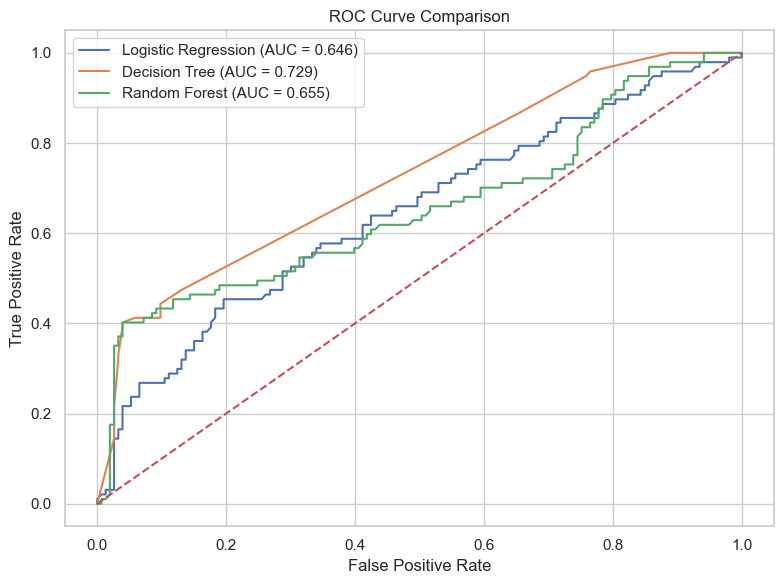

TOP IMPORTANT FEATURES:
                                                  Feature  Importance
                                    numeric__AnnualIncome    0.307499
                           numeric__IncomePerFamilyMember    0.162698
                                             numeric__Age    0.156825
                                   numeric__FamilyMembers    0.107299
                     categorical__EverTravelledAbroad_Yes    0.071982
                      categorical__EverTravelledAbroad_No    0.061453
                                 numeric__ChronicDiseases    0.032336
                           categorical__FrequentFlyer_Yes    0.021628
                            categorical__FrequentFlyer_No    0.019839
           categorical__Employment Type_Government Sector    0.015141
categorical__Employment Type_Private Sector/Self Employed    0.014663
                            categorical__GraduateOrNot_No    0.014406
                           categorical__GraduateOrNot_Yes    0.014

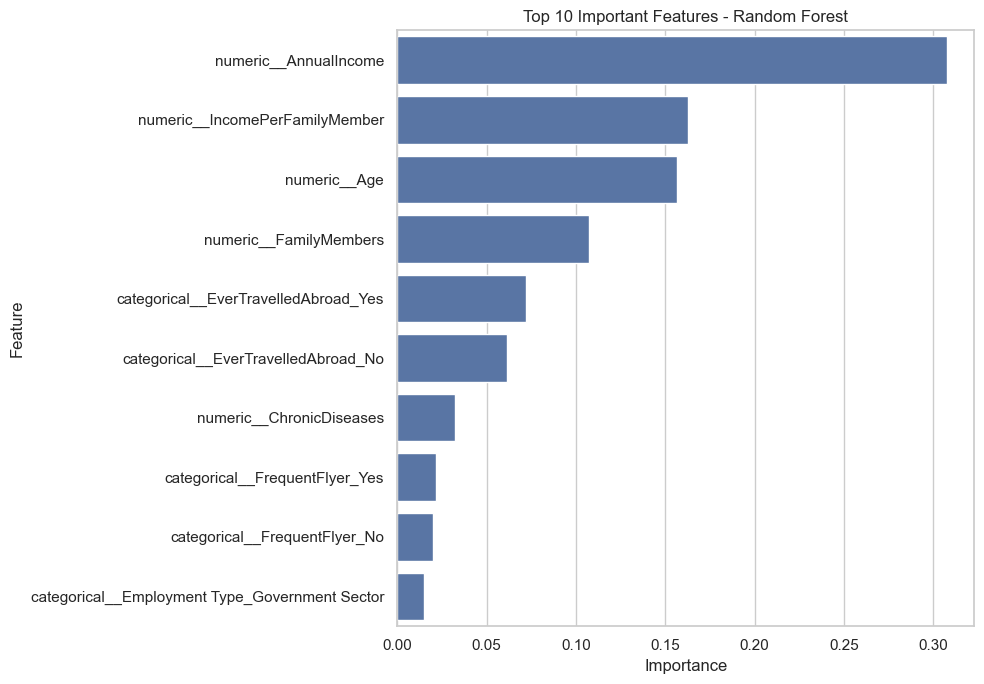

SAMPLE CUSTOMER PREDICTION:

Sample Customer:
   Age               Employment Type GraduateOrNot  AnnualIncome  \
0   35  Private Sector/Self Employed           Yes       1000000   

   FamilyMembers  ChronicDiseases FrequentFlyer EverTravelledAbroad  \
0              4                0           Yes                 Yes   

   IncomePerFamilyMember  
0               250000.0  

Prediction: Customer is unlikely to purchase Travel Insurance.
Purchase Probability: 50.00%
KEY PROJECT INSIGHTS:

1. Travel insurance purchase decisions can be influenced
   by demographic, financial and travel-related factors.

2. Annual income provides useful information about
   customer purchasing behaviour.

3. Frequent flyer status and previous overseas travel
   capture important travel behaviour.

4. Age and family size provide additional customer
   characteristics for prediction.

5. Three classification models were implemented:
   Logistic Regression, Decision Tree and Random Forest.

6. Models were 

In [9]:



# 1. IMPORT LIBRARIES


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")



# 2. LOAD DATASET


print("TRAVEL INSURANCE PURCHASE PREDICTION:")


df = pd.read_csv("TravelInsurancePrediction.csv")

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)



# 3. INITIAL DATA INSPECTION


print("INITIAL DATA INSPECTION:")

print("\nFirst 5 rows:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())



# 4. MISSING VALUE CHECK


print("MISSING VALUE CHECK:")

missing_values = df.isnull().sum()

print(missing_values)

if missing_values.sum() == 0:
    print("\nNo missing values found.")
else:
    print("\nMissing values found. Handling them...")

    for column in df.columns:
        if df[column].dtype == "object":
            df[column] = df[column].fillna(
                df[column].mode()[0]
            )
        else:
            df[column] = df[column].fillna(
                df[column].median()
            )



# 5. REMOVE UNNECESSARY INDEX COLUMN


if "Unnamed: 0" in df.columns:

    df.drop(
        "Unnamed: 0",
        axis=1,
        inplace=True
    )

    print("\nRemoved unnecessary 'Unnamed: 0' column.")



# 6. DUPLICATE CHECK


print("DUPLICATE CHECK:")

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

if duplicate_count > 0:

    df.drop_duplicates(
        inplace=True
    )

    print("Duplicate rows removed.")

else:

    print("No duplicate rows found.")


# 7. TARGET DISTRIBUTION

print("TARGET VARIABLE DISTRIBUTION:")

print(
    df["TravelInsurance"].value_counts()
)

print("\nTarget percentage:")

print(
    df["TravelInsurance"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)



# 8. EXPLORATORY DATA ANALYSIS


print("EXPLORATORY DATA ANALYSIS:")




# 8.1 Age Distribution


plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()



# 8.2 Annual Income Distribution


plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="AnnualIncome",
    bins=20,
    kde=True
)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# 8.3 Travel Insurance Distribution

plt.figure(figsize=(6, 5))

sns.countplot(
    data=df,
    x="TravelInsurance"
)

plt.title("Travel Insurance Purchase Distribution")
plt.xlabel("Travel Insurance (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# 8.4 Employment Type

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Employment Type",
    hue="TravelInsurance"
)

plt.title("Employment Type vs Travel Insurance Purchase")
plt.xlabel("Employment Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# 8.5 Frequent Flyer


plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="FrequentFlyer",
    hue="TravelInsurance"
)

plt.title("Frequent Flyer vs Travel Insurance Purchase")
plt.xlabel("Frequent Flyer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# 8.6 Previous Overseas Travel

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="EverTravelledAbroad",
    hue="TravelInsurance"
)

plt.title("Previous Overseas Travel vs Insurance Purchase")
plt.xlabel("Ever Travelled Abroad")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# 8.7 Graduate Status

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="GraduateOrNot",
    hue="TravelInsurance"
)

plt.title("Graduate Status vs Insurance Purchase")
plt.xlabel("Graduate Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# 8.8 Age vs Insurance

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="TravelInsurance",
    y="Age"
)

plt.title("Age vs Travel Insurance Purchase")
plt.xlabel("Travel Insurance")
plt.ylabel("Age")
plt.tight_layout()
plt.show()


# 8.9 Income vs Insurance

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="TravelInsurance",
    y="AnnualIncome"
)

plt.title("Annual Income vs Travel Insurance Purchase")
plt.xlabel("Travel Insurance")
plt.ylabel("Annual Income")
plt.tight_layout()
plt.show()


# 9. OUTLIER CHECK

print("OUTLIER CHECK:")

numeric_columns = [
    "Age",
    "AnnualIncome",
    "FamilyMembers"
]

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(
        f"{column}: {len(outliers)} potential outliers"
    )


# 10. CORRELATION HEATMAP

print("CORRELATION ANALYSIS:")

correlation_data = df.copy()

categorical_columns = [
    "Employment Type",
    "GraduateOrNot",
    "FrequentFlyer",
    "EverTravelledAbroad"
]

for column in categorical_columns:

    correlation_data[column] = pd.factorize(
        correlation_data[column]
    )[0]

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# 11. FEATURE ENGINEERING

print("FEATURE ENGINEERING:")

df["IncomePerFamilyMember"] = (
    df["AnnualIncome"] /
    df["FamilyMembers"]
)

print(
    "Created feature: IncomePerFamilyMember"
)

print("\nUpdated columns:")
print(df.columns.tolist())


# 12. FEATURES AND TARGET

X = df.drop(
    "TravelInsurance",
    axis=1
)

y = df["TravelInsurance"]

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print("TravelInsurance")


# 13. CATEGORICAL AND NUMERICAL FEATURES

categorical_features = [
    "Employment Type",
    "GraduateOrNot",
    "FrequentFlyer",
    "EverTravelledAbroad"
]

numeric_features = [
    "Age",
    "AnnualIncome",
    "FamilyMembers",
    "ChronicDiseases",
    "IncomePerFamilyMember"
]


# 14. PREPROCESSING

preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",

            StandardScaler(),

            numeric_features
        ),

        (
            "categorical",

            OneHotEncoder(
                handle_unknown="ignore"
            ),

            categorical_features
        )
    ]
)


# 15. TRAIN TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print("TRAIN TEST SPLIT:")

print(
    "Training samples:",
    X_train.shape[0]
)

print(
    "Testing samples:",
    X_test.shape[0]
)


# 16. MACHINE LEARNING MODELS

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            max_depth=8,
            random_state=42
        )
}


# 17. TRAIN AND EVALUATE MODELS

results = []

trained_models = {}

print("MODEL TRAINING AND EVALUATION:")

for model_name, model in models.items():

    pipeline = Pipeline(

        steps=[

            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                model
            )
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    y_pred = pipeline.predict(
        X_test
    )

    y_probability = pipeline.predict_proba(
        X_test
    )[:, 1]

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        y_probability
    )

    results.append({

        "Model": model_name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1,

        "ROC-AUC": roc_auc
    })

    trained_models[
        model_name
    ] = pipeline

    print("\n" + "-" * 60)

    print(model_name)

    print("-" * 60)

    print(
        f"Accuracy : {accuracy:.4f}"
    )

    print(
        f"Precision: {precision:.4f}"
    )

    print(
        f"Recall   : {recall:.4f}"
    )

    print(
        f"F1 Score : {f1:.4f}"
    )

    print(
        f"ROC-AUC  : {roc_auc:.4f}"
    )


# 18. MODEL COMPARISON

results_df = pd.DataFrame(
    results
)

print("MODEL COMPARISON:")

print(
    results_df.to_string(
        index=False
    )
)


# 19. MODEL COMPARISON GRAPH

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_melted = results_df.melt(

    id_vars="Model",

    value_vars=metrics,

    var_name="Metric",

    value_name="Score"
)

plt.figure(
    figsize=(12, 6)
)

sns.barplot(

    data=results_melted,

    x="Model",

    y="Score",

    hue="Metric"
)

plt.title(
    "Machine Learning Model Comparison"
)

plt.xlabel("Model")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()


# 20. SELECT BEST MODEL

best_model_name = results_df.loc[

    results_df["F1 Score"].idxmax(),

    "Model"
]

best_model = trained_models[
    best_model_name
]

print("SELECTED MODEL:")

print(
    "Selected model:",
    best_model_name
)

print(
    "Selection basis: Highest F1 Score"
)


# 21. CONFUSION MATRIX

best_predictions = best_model.predict(
    X_test
)

cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=[
        "No Insurance",
        "Insurance"
    ],

    yticklabels=[
        "No Insurance",
        "Insurance"
    ]
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.tight_layout()

plt.show()


# 22. CLASSIFICATION REPORT

print("CLASSIFICATION REPORT:")

print(
    classification_report(
        y_test,
        best_predictions
    )
)


# 23. ROC CURVE

plt.figure(
    figsize=(8, 6)
)

for model_name, model in trained_models.items():

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(

        fpr,

        tpr,

        label=f"{model_name} (AUC = {auc_score:.3f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title(
    "ROC Curve Comparison"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()

plt.tight_layout()

plt.show()


# 24. RANDOM FOREST FEATURE IMPORTANCE

rf_pipeline = trained_models[
    "Random Forest"
]

rf_model = rf_pipeline.named_steps[
    "model"
]

rf_preprocessor = rf_pipeline.named_steps[
    "preprocessor"
]

feature_names = (
    rf_preprocessor
    .get_feature_names_out()
)

importance = (
    rf_model.feature_importances_
)

feature_importance_df = pd.DataFrame({

    "Feature": feature_names,

    "Importance": importance

})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
)

print("TOP IMPORTANT FEATURES:")

print(
    feature_importance_df
    .head(15)
    .to_string(index=False)
)


# 25. FEATURE IMPORTANCE GRAPH

top_features = (
    feature_importance_df
    .head(10)
)

plt.figure(
    figsize=(10, 7)
)

sns.barplot(

    data=top_features,

    x="Importance",

    y="Feature"
)

plt.title(
    "Top 10 Important Features - Random Forest"
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.show()


# 26. SAMPLE CUSTOMER PREDICTION

print("SAMPLE CUSTOMER PREDICTION:")

sample_customer = pd.DataFrame({

    "Age": [35],

    "Employment Type":
        ["Private Sector/Self Employed"],

    "GraduateOrNot":
        ["Yes"],

    "AnnualIncome":
        [1000000],

    "FamilyMembers":
        [4],

    "ChronicDiseases":
        [0],

    "FrequentFlyer":
        ["Yes"],

    "EverTravelledAbroad":
        ["Yes"]
})


sample_customer[
    "IncomePerFamilyMember"
] = (

    sample_customer[
        "AnnualIncome"
    ]

    /

    sample_customer[
        "FamilyMembers"
    ]
)


prediction = best_model.predict(
    sample_customer
)

probability = (
    best_model
    .predict_proba(
        sample_customer
    )[0][1]
)


print("\nSample Customer:")

print(
    sample_customer
)


if prediction[0] == 1:

    print(
        "\nPrediction: Customer is likely to purchase Travel Insurance."
    )

else:

    print(
        "\nPrediction: Customer is unlikely to purchase Travel Insurance."
    )


print(
    f"Purchase Probability: {probability:.2%}"
)


# 27. KEY INSIGHTS

print("KEY PROJECT INSIGHTS:")
print("=" * 70)
print("""
1. Travel insurance purchase decisions can be influenced
   by demographic, financial and travel-related factors.

2. Annual income provides useful information about
   customer purchasing behaviour.

3. Frequent flyer status and previous overseas travel
   capture important travel behaviour.

4. Age and family size provide additional customer
   characteristics for prediction.

5. Three classification models were implemented:
   Logistic Regression, Decision Tree and Random Forest.

6. Models were compared using Accuracy, Precision,
   Recall, F1 Score and ROC-AUC.

7. The model with the highest F1 Score was selected
   as the final model.

8. Feature importance from Random Forest helps identify
   the variables that contribute most to prediction.
""")


# 28. FINAL SUMMARY

print("PROJECT COMPLETED SUCCESSFULLY:")

print(
    "\nFinal Dataset Shape:",
    df.shape
)

print("\nModels Tested:")

for model_name in models.keys():

    print(
        "-",
        model_name
    )

print(
    "\nSelected Model:",
    best_model_name
)

print("\nFinal Model Performance:")

final_result = results_df[
    results_df["Model"] ==
    best_model_name
]

print(
    final_result.to_string(
        index=False
    )
)

print("\nThank you!")

In [10]:
print("Original rows: 1987")
print("Rows after duplicate removal:", len(df))
print("Duplicate rows removed:", 1987 - len(df))

Original rows: 1987
Rows after duplicate removal: 1249
Duplicate rows removed: 738


In [11]:
original_df = pd.read_csv("TravelInsurancePrediction.csv")

if "Unnamed: 0" in original_df.columns:
    original_df = original_df.drop("Unnamed: 0", axis=1)

duplicate_rows = original_df[
    original_df.duplicated(keep=False)
]

print("Total original rows:", len(original_df))
print("Unique rows:", len(original_df.drop_duplicates()))
print("Duplicate rows:", original_df.duplicated().sum())
print("Duplicate groups:", duplicate_rows.drop_duplicates().shape[0])

print("\nMost repeated records:")
print(
    duplicate_rows
    .value_counts()
    .head(10)
)


Total original rows: 1987
Unique rows: 1249
Duplicate rows: 738
Duplicate groups: 382

Most repeated records:
Age  Employment Type               GraduateOrNot  AnnualIncome  FamilyMembers  ChronicDiseases  FrequentFlyer  EverTravelledAbroad  TravelInsurance
28   Government Sector             Yes            300000        4              0                No             No                   0                  12
29   Private Sector/Self Employed  Yes            1200000       4              0                No             No                   0                  11
28   Government Sector             Yes            300000        5              0                No             No                   0                  10
     Private Sector/Self Employed  Yes            800000        4              0                No             No                   0                  10
                                                  1100000       4              0                No             No             